In [1]:
import openmc
import numpy as np
import math
import matplotlib.pyplot as plt
from fusion_fuel_concepts_explorer.sources import SteadyStateSource
from fusion_fuel_concepts_explorer.geometry import component_nodes as cn

import h5py

In [2]:
avg_density_Dhe3 = 1.3e20
avg_temperature_Dhe3 = 70.0
density_peaking_DHe3 = 2.5
temperature_peaking_DHe3 = 2
density_profile_DHe3 = lambda rho: avg_density_Dhe3 * density_peaking_DHe3 * ((1.0 - rho**2.0) ** (density_peaking_DHe3 - 1.0))
temperature_profile_DHe3 = lambda rho: avg_temperature_Dhe3 * temperature_peaking_DHe3 * ((1.0 - rho**2.0) ** (temperature_peaking_DHe3 - 1.0))

DHe3_source = SteadyStateSource(
    source_type="DHe3",
    volume_m3=150.0,
    n_i=density_profile_DHe3,
    T_i=temperature_profile_DHe3,
    tau_p=2.5,
)

number_of_neutrons_per_second_dhe = DHe3_source.reaction_rates_s['DT'] + DHe3_source.reaction_rates_s['DDn'] + DHe3_source.reaction_rates_s['TT'] + DHe3_source.reaction_rates_s['THe3_np']
print("D-He3: Number of neutrons per second", number_of_neutrons_per_second_dhe, '\n')
eV_to_Jouls = 1.60218e-19

# Volume (to be calculated)
tf_coil_magnet_volume = 337409.34 # * 18 if reflective BC.. TBV
tf_coil_insulation_volume = 2990501.95 # * 18
tf_coil_case_volume = 4881775.41 # * 18
ybco_volume = 0.01 * tf_coil_magnet_volume # about 1% of the total (literature), according to the definition in OpenMC it would be 0.72%

D-He3: Number of neutrons per second 1.589518216296959e+19 



# Flux

In [3]:
sp_dhe = openmc.StatePoint("../statepoint.500.h5")
sp_dt = openmc.StatePoint("results/statepoint.500.h5")

In [4]:
def compare_flux_spectra(
    sp1, name1, volume1, number_of_neutrons_per_second1,
    sp2, name2, volume2, number_of_neutrons_per_second2,
    label1="Case 1", label2="Case 2", region_name="Region A"
):

    energy_bins = openmc.mgxs.GROUP_STRUCTURES['TRIPOLI-315']
    energy_filter = openmc.EnergyFilter(energy_bins)
    E = energy_filter.values[:-1] / 1e6

    def get_flux_spectrum(sp, name, volume, number_of_neutrons_per_second):
        tally = sp.get_tally(name=name)

        mean = np.asarray(tally.mean)
        std = np.asarray(tally.std_dev)

        n_energy = len(energy_bins) - 1
        n_cells = int(len(mean) / n_energy)

        mean = mean.reshape((n_cells, n_energy))
        std = std.reshape((n_cells, n_energy))

        flux = mean.sum(axis=0)
        flux_std = np.sqrt((std**2).sum(axis=0))

        flux_region = (flux / volume) * number_of_neutrons_per_second
        flux_err = (flux_std / volume) * number_of_neutrons_per_second

        return flux_region, flux_err

    flux1, err1 = get_flux_spectrum(
        sp1, name1, volume1, number_of_neutrons_per_second1
    )
    flux2, err2 = get_flux_spectrum(
        sp2, name2, volume2, number_of_neutrons_per_second2
    )

    plt.figure(figsize=(8, 6))

    plt.step(E, flux1, where='post', label=label1)
    plt.fill_between(
        E,
        flux1 - 3 * err1,
        flux1 + 3 * err1,
        step='post',
        alpha=0.20
    )

    plt.step(E, flux2, where='post', label=label2)
    plt.fill_between(
        E,
        flux2 - 3 * err2,
        flux2 + 3 * err2,
        step='post',
        alpha=0.20
    )

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energy [MeV]')
    plt.ylabel('Flux [n/cm²/s]')
    plt.xlim(2e-7, 30)
    plt.grid(alpha=0.2, which='both')
    plt.legend()
    plt.title(f"Flux spectrum comparison on {region_name}")
    plt.savefig(f"{region_name}.pdf", format="pdf")
    plt.show()

    def print_integrated_flux(label, flux_region, flux_err):
        flux_total = flux_region.sum()
        flux_total_std = np.sqrt((flux_err**2).sum())

        flux_above_7 = flux_region[E > 7].sum()
        flux_above_7_std = np.sqrt((flux_err[E > 7]**2).sum())

        flux_1_to_7 = flux_region[(E >= 1) & (E <= 7)].sum()
        flux_1_to_7_std = np.sqrt((flux_err[(E >= 1) & (E <= 7)]**2).sum())

        flux_below_1 = flux_region[E < 1].sum()
        flux_below_1_std = np.sqrt((flux_err[E < 1]**2).sum())

        print(f"\n--- {label} ---")
        print(f"Total flux   = {flux_total:.3e} ± {flux_total_std:.3e} n/cm²/s")
        print(f"Flux > 7 MeV = {flux_above_7:.3e} ± {flux_above_7_std:.3e} n/cm²/s")
        print(f"Flux 1–7 MeV = {flux_1_to_7:.3e} ± {flux_1_to_7_std:.3e} n/cm²/s")
        print(f"Flux < 1 MeV = {flux_below_1:.3e} ± {flux_below_1_std:.3e} n/cm²/s")

    print_integrated_flux(label1, flux1, err1)
    print_integrated_flux(label2, flux2, err2)

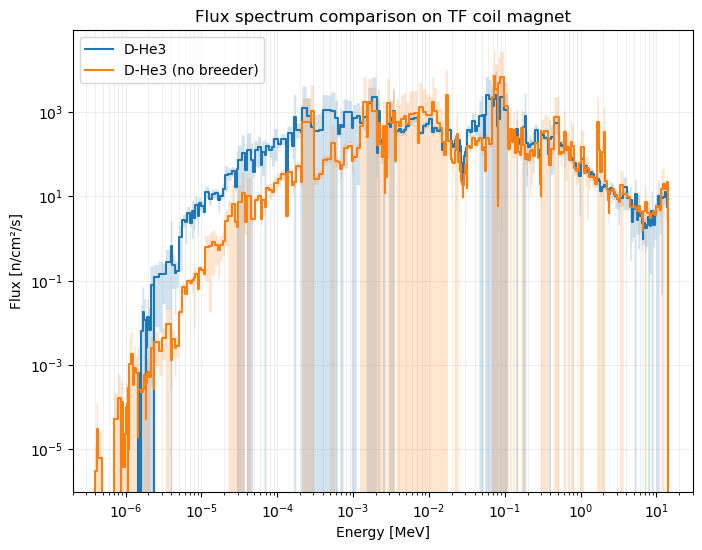


--- D-He3 ---
Total flux   = 6.642e+04 ± 4.686e+03 n/cm²/s
Flux > 7 MeV = 8.763e+01 ± 8.157e+00 n/cm²/s
Flux 1–7 MeV = 6.689e+02 ± 1.520e+01 n/cm²/s
Flux < 1 MeV = 6.566e+04 ± 4.686e+03 n/cm²/s

--- D-He3 (no breeder) ---
Total flux   = 7.166e+04 ± 1.286e+04 n/cm²/s
Flux > 7 MeV = 1.316e+02 ± 1.404e+01 n/cm²/s
Flux 1–7 MeV = 1.815e+03 ± 6.518e+02 n/cm²/s
Flux < 1 MeV = 6.972e+04 ± 1.284e+04 n/cm²/s


In [5]:
compare_flux_spectra(
    sp1=sp_dhe,
    name1="neutron_spectra_tf_coil_magnet",
    volume1=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dhe,
    sp2=sp_dt,
    name2="neutron_spectra_tf_coil_magnet",
    volume2=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dhe,
    label1="D-He3",
    label2="D-He3 (no breeder)",
    region_name="TF coil magnet"
)

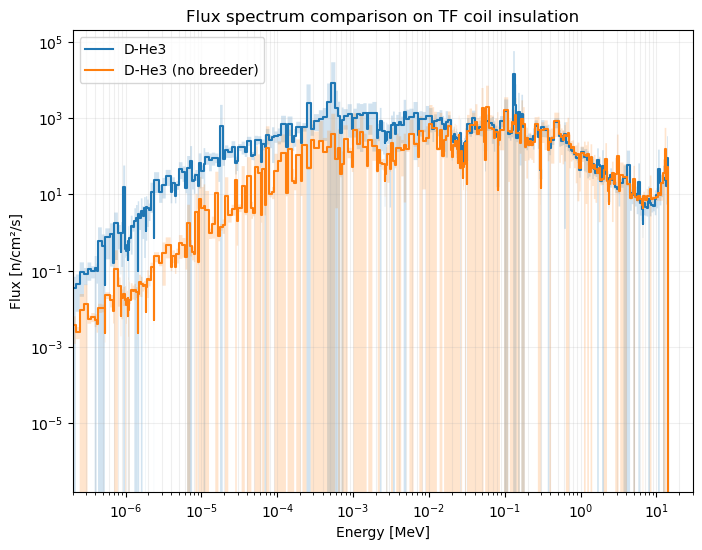


--- D-He3 ---
Total flux   = 1.128e+05 ± 1.635e+04 n/cm²/s
Flux > 7 MeV = 2.922e+02 ± 9.005e+01 n/cm²/s
Flux 1–7 MeV = 1.351e+03 ± 6.719e+01 n/cm²/s
Flux < 1 MeV = 1.111e+05 ± 1.635e+04 n/cm²/s

--- D-He3 (no breeder) ---
Total flux   = 4.431e+04 ± 3.082e+03 n/cm²/s
Flux > 7 MeV = 3.827e+02 ± 1.333e+02 n/cm²/s
Flux 1–7 MeV = 1.463e+03 ± 1.354e+02 n/cm²/s
Flux < 1 MeV = 4.247e+04 ± 3.076e+03 n/cm²/s


In [6]:
compare_flux_spectra(
    sp1=sp_dhe,
    name1="neutron_spectra_tf_coil_insulation",
    volume1=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dhe,
    sp2=sp_dt,
    name2="neutron_spectra_tf_coil_insulation",
    volume2=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dhe,
    label1="D-He3",
    label2="D-He3 (no breeder)",
    region_name="TF coil insulation"
)

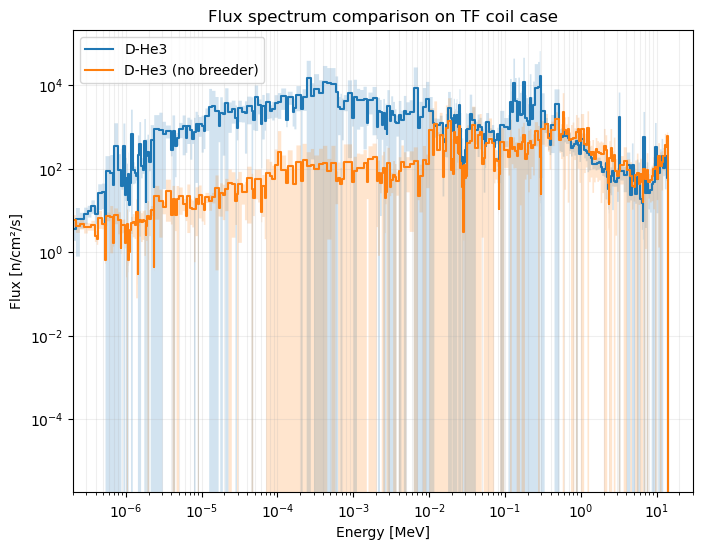


--- D-He3 ---
Total flux   = 4.731e+05 ± 3.226e+04 n/cm²/s
Flux > 7 MeV = 1.502e+03 ± 3.392e+02 n/cm²/s
Flux 1–7 MeV = 6.254e+03 ± 1.768e+03 n/cm²/s
Flux < 1 MeV = 4.653e+05 ± 3.221e+04 n/cm²/s

--- D-He3 (no breeder) ---
Total flux   = 5.866e+04 ± 3.137e+03 n/cm²/s
Flux > 7 MeV = 2.591e+03 ± 1.753e+02 n/cm²/s
Flux 1–7 MeV = 7.596e+03 ± 7.468e+02 n/cm²/s
Flux < 1 MeV = 4.847e+04 ± 3.042e+03 n/cm²/s


In [7]:
compare_flux_spectra(
    sp1=sp_dhe,
    name1="neutron_spectra_tf_coil_case",
    volume1=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dhe,
    sp2=sp_dt,
    name2="neutron_spectra_tf_coil_case",
    volume2=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dhe,
    label1="D-He3",
    label2="D-He3 (no breeder)",
    region_name="TF coil case"
)